In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.signal import savgol_filter
from sklearn.decomposition import FastICA
import padasip as pa
import IPython.display as ipd

matplotlib.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

from setup_dsp import *


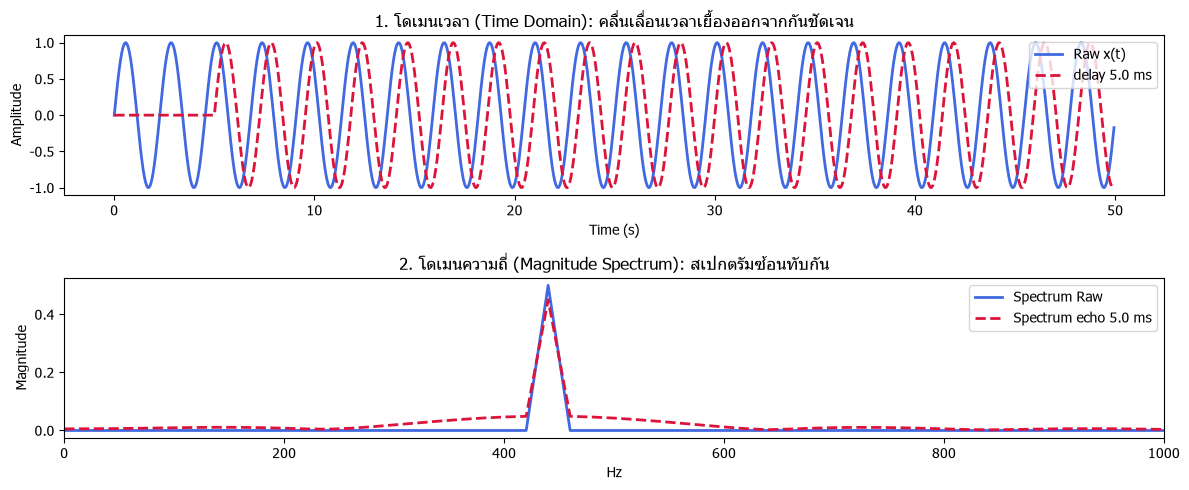

In [2]:
fs = 16000           
duration = 0.05
t = time_axis(fs, duration)
raw = generate_sine(440,t)
echo = generate_sine(440,t)
delay_ms = 5.0
delay_samples = int(fs * delay_ms / 1000.0)
echo = np.zeros_like(raw)
echo[delay_samples:] = raw[:-delay_samples]

N = len(raw)
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_raw = np.abs(np.fft.rfft(raw)) / N
mag_echo = np.abs(np.fft.rfft(echo)) / N


plt.figure(figsize=(12,5))
plt.subplot(2,1,1)
plt.plot(t * 1000,raw, label="Raw x(t)", color="royalblue", lw=2)
plt.plot(t * 1000, echo, label=f"delay {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("1. โดเมนเวลา (Time Domain): คลื่นเลื่อนเวลาเยื้องออกจากกันชัดเจน")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.tight_layout()

plt.subplot(2,1,2)
plt.plot(freqs, mag_raw, label="Spectrum Raw", color="royalblue", lw=2)
plt.plot(freqs, mag_echo, label=f"Spectrum echo {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("2. โดเมนความถี่ (Magnitude Spectrum): สเปกตรัมซ้อนทับกัน")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.legend(loc="upper right")
plt.xlim(0, 1000)
plt.tight_layout()


[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 10.00 ms (160 samples)


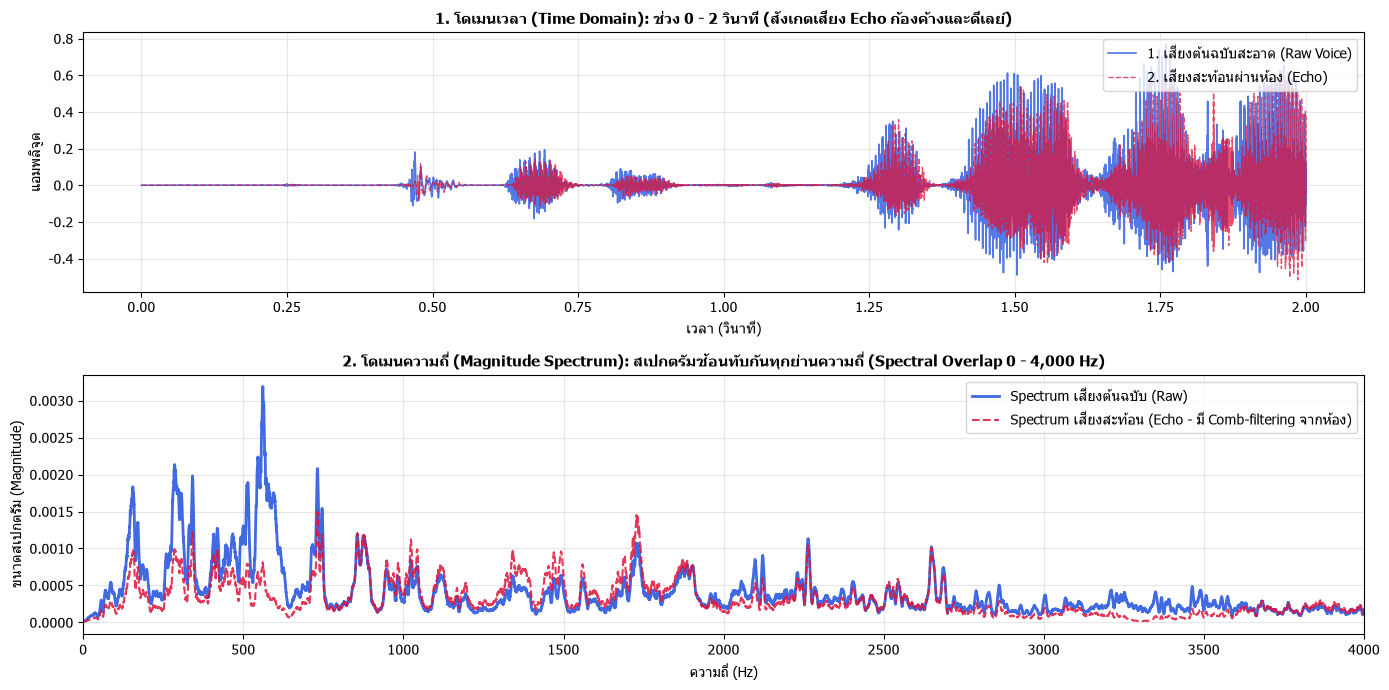

🔊 [1. เสียงต้นฉบับสะอาด (Clean Raw Voice)]:


🔊 [2. เสียงสะท้อนก้องในห้อง (Room Echo)]:


In [3]:
# 1. ดึงสัญญาณเสียงคนพูดจริง (Far-End) และเสียงสะท้อนผ่านห้อง (Echo)
t, raw, echo, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=10.0)

# 2. คำนวณ Magnitude Spectrum ด้วยฟังก์ชัน spectrum() ของเรา
freqs, mag_raw = spectrum(raw, fs=fs)
_, mag_echo = spectrum(echo, fs=fs)

# 3. เกลี่ยให้เรียบ (Smoothing) ด้วย savgol_filter เพื่อให้มองเห็นโครงสร้าง Formants เสียงมนุษย์ได้ชัดเจน
mag_raw_smooth = savgol_filter(mag_raw, window_length=101, polyorder=3)
mag_echo_smooth = savgol_filter(mag_echo, window_length=101, polyorder=3)

# 4. พล็อตกราฟเปรียบเทียบ Time Domain และ Frequency Domain
plt.figure(figsize=(14, 7))

# 4.1 โดเมนเวลา (Time Domain)
plt.subplot(2, 1, 1)
plt.plot(t[:fs * 2], raw[:fs * 2], label="1. เสียงต้นฉบับสะอาด (Raw Voice)", color="royalblue", lw=1.2, alpha=0.9)
plt.plot(t[:fs * 2], echo[:fs * 2], label="2. เสียงสะท้อนผ่านห้อง (Echo)", color="crimson", lw=1.0, linestyle="--", alpha=0.75)
plt.title("1. โดเมนเวลา (Time Domain): ช่วง 0 - 2 วินาที (สังเกตเสียง Echo ก้องค้างและดีเลย์)", fontsize=11, fontweight="bold")
plt.xlabel("เวลา (วินาที)")
plt.ylabel("แอมพลิจูด")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

# 4.2 โดเมนความถี่ (Magnitude Spectrum)
plt.subplot(2, 1, 2)
plt.plot(freqs, mag_raw_smooth, label="Spectrum เสียงต้นฉบับ (Raw)", color="royalblue", lw=2.0)
plt.plot(freqs, mag_echo_smooth, label="Spectrum เสียงสะท้อน (Echo - มี Comb-filtering จากห้อง)", color="crimson", lw=1.5, linestyle="--", alpha=0.85)
plt.title("2. โดเมนความถี่ (Magnitude Spectrum): สเปกตรัมซ้อนทับกันทุกย่านความถี่ (Spectral Overlap 0 - 4,000 Hz)", fontsize=11, fontweight="bold")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("ขนาดสเปกตรัม (Magnitude)")
plt.xlim(0, 4000)
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. เครื่องเล่นเสียงสำหรับกดฟังเปรียบเทียบ
print("🔊 [1. เสียงต้นฉบับสะอาด (Clean Raw Voice)]:")
ipd.display(ipd.Audio(raw, rate=fs))

print("🔊 [2. เสียงสะท้อนก้องในห้อง (Room Echo)]:")
ipd.display(ipd.Audio(echo, rate=fs))
